
# Lab 8: Monte Carlo Markov Chain (MCMC)

**Exercise 1**:

* 1. Compute $\int_0^4 x^{1/2} dx$ and compare with an analytic result.
* 2.  Compute the double integral of $x\,y^2$ over the box x ranging from $0$ to $2$ and $y$ ranging from $0$ to $1$. That is,

$$\int_{x=0}^{x=2} \int_{y=0}^{y=1} xy^2 dy dx$$

In [7]:
import numpy as np
import random
import pandas as pd
import math
import scipy.integrate as integrate
import matplotlib.pyplot as plt

In [ ]:
# 1.A). Integral 1D

# Scipy

def f(x):
  return np.sqrt(x)

integral_analitica_1d = integrate.quad(f,0,4)

# Montecarlo

def montercarlo_1D(f,a,b,n):
  x = np.random.uniform(a,b,n)
  return np.mean(f(x)) * (b-a)

integral_montecarlo_1d = montercarlo_1D(f,0,4,1000)

error = np.abs(integral_analitica_1d[0] - integral_montecarlo_1d)
print("Integral analitica: ", integral_analitica_1d[0])
print("Integral montecarlo: ", integral_montecarlo_1d)
print("Error: ", error)

Integral analitica:  5.333333333333335
Integral montecarlo:  5.321328387331295
Error:  0.012004946002039496


In [ ]:
# 1.B). Integral 2D

# Scipy

f_2d = lambda x,y: x*y**2

integral_analitica_2d = integrate.dblquad(f_2d,0,2,0,1)

# Montecarlo

def montercarlo_2D(f,ax,bx,ay,by,n):
  x = np.random.uniform(ax,bx,n)
  y = np.random.uniform(ay,by,n)
  area = (bx-ax)*(by-ay)
  return np.mean(f(x,y))*area

integral_montercarlo_2d = montercarlo_2D(f_2d,0,2,0,1,1000)

error = np.abs(integral_analitica_2d[0] - integral_montercarlo_2d)

print("Integral analitica: ", integral_analitica_2d[0])
print("Integral montecarlo: ", integral_montercarlo_2d)
print("Error: ", error)

Integral analitica:  1.3333333333333335
Integral montecarlo:  0.7137474012627093
Error:  0.6195859320706242


**Exercise 2**:

Read about the Ising's model 1D, 2D and 3D.

## Modelo de Ising 2D

Como aplicación de la distribución canónica en `Física estadística` tenemos el **modelo de Ising**.
Para el caso de un material paramagnético de átomos de spin $1/2$ y momento magnetico $\mu_0$ en presencia de un campo magnético externo $H$, se ha determinado experimentalmente que la magnetización media depende del campo magnético y la temperatura del material (https://en.wikipedia.org/wiki/Ising_model).

Considere un sistema compuesto por $N$ átomos no interactuantes en un material 2D, a una temperatura $T$ y en presencia de un campo magnético externo $H$ que está orientado en cierta dirección fija respecto al material.

<img src="https://upload.wikimedia.org/wikipedia/commons/f/fe/2D_ising_model_on_lattice.svg" width="550">

1. Realizar la simulación de este sistema con el método de **Metrópolis Monte Carlo** (ver notebook). Visitar todos los
posibles spines de la red cristalina del material e intentear inversiones bajo condiciones adecuadas de energía y estabilidad del sistema. *Considere interacción con los primeros vecinos*.

2. Graficar la Magnetización media del material vs el campo magnetico para tres temperaturas reducidas (H/T) con $T=\{5,10,15\}$ K (Kelvin) y un campo variable $-30\,T < H < +30\,T$.  

In [5]:
# Constantes

k_B = 1.380649e-23
mu_B = 9.2740100783e-24
C = mu_B / k_B
J = 1.0  # Acoplamiento

# Parametros

n = 10  # Red de 10x10
MC_steps = 200
temperaturas = [5, 10, 15]
campos_H = np.arange(-30, 31, 0.5)
np.random.seed(1)

In [6]:
# Estado inicial del sistema

red = np.random.choice([-1, 1], size=(n, n))
resultados = []

# Iterar sobre T y H
for T in temperaturas:
    for H in campos_H:
        # Acumulador de magnetizacion
        Mag_acumulada = 0

        # Pasos de Monte Carlo
        for m in range(MC_steps):
            # Recorrer todos los sitios de la red
            for i in range(n):
                for j in range(n):
                    # Valor del espin actual
                    s = red[i, j]

                    # Suma de los 4 primeros vecinos
                    vecinos = (red[(i + 1) % n, j] +
                               red[(i - 1) % n, j] +
                               red[i, (j + 1) % n] +
                               red[i, (j - 1) % n])

                    # Diferencia de energia delta E
                    deltaE = 2 * s * (J * vecinos + C * H)

                    # Criterio de Metropolis
                    if deltaE <= 0:
                        red[i, j] = -s
                    else:
                        prob = np.exp(-deltaE / T)
                        if np.random.rand() < prob:
                            red[i, j] = -s

                    # Acumular magnetizacion actual
                    Mag_acumulada += red[i, j]

        # Magnetizacion promedio por espin
        Mag_media = Mag_acumulada / (MC_steps * n * n)
        resultados.append([T, H, Mag_media])


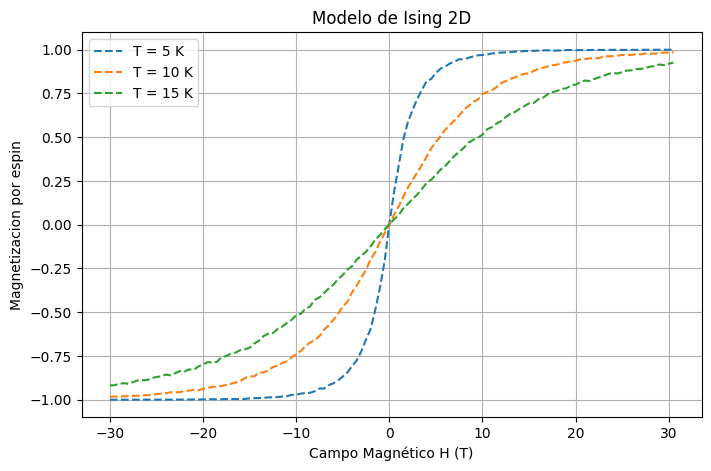

In [16]:
df = pd.DataFrame(resultados, columns=['T', 'H', 'Magnetizacion'])

plt.figure(figsize=(8, 5))
for T in temperaturas:
    datos = df[df['T'] == T]
    plt.plot(datos['H'], datos['Magnetizacion'], label=f'T = {T} K', linestyle = "--")

plt.xlabel('Campo Magnético H (T)')
plt.ylabel('Magnetizacion por espin')
plt.title('Modelo de Ising 2D')
plt.legend()
plt.grid(True)
plt.show()